# Fig 3 K-M on the first vs second half of each treadmill trial

Reviewer control: is the RS/OF tuning-ellipse orientation distribution (Fig 3 K-M) driven by
residual activity from the acceleration ramp? The trial-averaged g2d fits were redone with each
trial's analysis window (plateau onset + 0.5 s, RS-to-motor filter computed on the continuous
trace) cut to its first or second half (`precompute_data/fit_treadmill_halves.py`, NEMO job
63727541). `full` is the same code without the split, a reproduction check of the production
`_treadmill_trial_average_plateau` columns.

Each variant goes through the exact Fig 3 pipeline: depth-selective in closed loop
(`is_depth_neuron`) and g2d test R² above the empirical null of that variant, elongation cut
1.4:1, axial von Mises mixture BIC for k = 1..5 (seed 42).

In [ ]:
%reload_ext autoreload
%autoreload 2
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import flexiznam as flz

from cottage_analysis.plotting import style
from cottage_analysis.plotting.style import CM, FONTSIZE_DICT
from v1_depth_map.figure_utils.treadmill import (
    load_treadmill_population_neurons_df,
    add_trial_average_rsof_columns,
)
from v1_depth_map.figure_utils.rsof_integration import plot_angle_eccentricity_polar
from v1_depth_map.figure_utils import von_mises as vm
from v1_depth_map.paths import get_figures_roots

style.setup_figure_fonts()
project = "colasa_3d-vision_revisions"
flexilims_session = flz.get_flexilims_session(project)
READ_ROOT, SAVE_ROOT = get_figures_roots(flexilims_session)
SAVE_ROOT.mkdir(parents=True, exist_ok=True)

HALVES_ROOT = (
    Path(flz.get_data_root("processed", flexilims_session=flexilims_session))
    / project
    / "analysis"
    / "treadmill_halves"
    / "results"
)
TA = "_treadmill_trial_average_plateau"  # production suffix, as in Fig 3
VARIANTS = ["full", "half1", "half2"]
ELONGATION_CUTOFF = 1.4  # same as Fig 3
MAX_K = 5

In [ ]:
(
    neurons_df_treadmill,
    _,
    _,
    valid_treadmill_sessions,
    treadmill_sessions,
) = load_treadmill_population_neurons_df(flexilims_session, load_simulated=False)
print(f"{len(neurons_df_treadmill)} neurons, {neurons_df_treadmill.session.nunique()} sessions")

Excluding session PZAG16.3b_S20250401: not V1
Excluding session PZAG22.1b_S20260303b: not V1


No combined folder found, loading iscell from individual planes.


No combined folder found, loading iscell from individual planes.


No combined folder found, loading iscell from individual planes.


No combined folder found, loading iscell from individual planes.


/Users/blota/Documents/code/v1_depth_map/v1_depth_map/figure_utils/treadmill.py:534: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  neurons_df["is_cell"] = s2p_io.load_is_cell(suite2p_ds.path_full)
/Users/blota/Documents/code/v1_depth_map/v1_depth_map/figure_utils/treadmill.py:546: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  neurons_df["session"] = session_name
/Users/blota/Documents/code/v1_depth_map/v1_depth_map/figure_utils/treadmill.py:547: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of c

... (7 outputs left out)

/Users/blota/Documents/code/v1_depth_map/v1_depth_map/figure_utils/treadmill.py:534: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  neurons_df["is_cell"] = s2p_io.load_is_cell(suite2p_ds.path_full)
/Users/blota/Documents/code/v1_depth_map/v1_depth_map/figure_utils/treadmill.py:534: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  neurons_df["is_cell"] = s2p_io.load_is_cell(suite2p_ds.path_full)


Depth selectivity not computed for session PZAG22.1f_S20260326, run basic analysis first
No combined folder found, loading iscell from individual planes.
Depth selectivity not computed for session PZAG22.1f_S20260331, run basic analysis first
4/11 valid sessions with treadmill depth data


940/2573 depth tuned neurons in closed loop
963/2573 depth tuned neurons in closed loop treadmill
266/2573 rsof neurons in closed loop treadmill
2573 neurons, 4 sessions


/Users/blota/Documents/code/v1_depth_map/v1_depth_map/figure_utils/treadmill.py:534: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  neurons_df["is_cell"] = s2p_io.load_is_cell(suite2p_ds.path_full)


In [ ]:
# Merge the half-trial fits under `{TA}_{variant}`. k1 carries the full-data popt, k5 the
# cross-validated test R^2 (same split as the production columns).
def load_variant(session, variant):
    d = HALVES_ROOT / session
    k1 = pd.read_pickle(d / STEM.format(1, variant))
    k5 = pd.read_pickle(d / STEM.format(5, variant))
    k5 = k5[["roi"] + [c for c in k5.columns if c not in k1.columns]]
    df = k1.merge(k5, on="roi", validate="one_to_one")
    return df.rename(columns={c: f"{c}{TA}_{variant}" for c in df.columns if c != "roi"})


sessions = sorted(neurons_df_treadmill.session.unique())
STEM = "fit_rs_of_tuning_gaussian_2d_k{}_treadmill_trial_average_legacy_plateau_{}.pickle"
missing_files = {
    v: [
        f"{s}/{STEM.format(k, v)}"
        for s in sessions
        for k in (1, 5)
        if not (HALVES_ROOT / s / STEM.format(k, v)).exists()
    ]
    for v in VARIANTS
}
for v, files in missing_files.items():
    if files:
        print(f"WARNING: skipping {v!r}, missing {len(files)} file(s): {files}")
VARIANTS = [v for v in VARIANTS if not missing_files[v]]
for variant in VARIANTS:
    fits = pd.concat(
        [load_variant(s, variant).assign(session=s) for s in sessions], ignore_index=True
    )
    n_before = len(neurons_df_treadmill)
    neurons_df_treadmill = neurons_df_treadmill.merge(
        fits, on=["session", "roi"], how="left", validate="one_to_one"
    )
    assert len(neurons_df_treadmill) == n_before
    missing = neurons_df_treadmill[f"rsof_test_rsq_closedloop_g2d{TA}_{variant}"].isna().mean()
    print(f"{variant}: merged, {missing:.1%} neurons without a test R^2")

full: merged, 0.0% neurons without a test R^2


half1: merged, 0.0% neurons without a test R^2


half2: merged, 0.0% neurons without a test R^2


In [ ]:
# Same derived columns, selection and von Mises model selection as Fig 3, per variant.
SUFFIXES = {"production": TA, **{v: f"{TA}_{v}" for v in VARIANTS}}
results = {}
for name, sfx in SUFFIXES.items():
    print(f"--- {name}")
    add_trial_average_rsof_columns(
        neurons_df_treadmill, ta_suffix=sfx, models=("g2d",), null_method="empirical"
    )
    ndf_polar = neurons_df_treadmill[
        neurons_df_treadmill[f"rsof_test_rsq_closedloop_g2d{sfx}_sig"]
        & neurons_df_treadmill["is_depth_neuron"].fillna(False)
    ].dropna(subset=[f"g2d_theta{sfx}", f"g2d_semimajor{sfx}", f"g2d_semiminor{sfx}"])
    elongation = ndf_polar[f"g2d_semimajor{sfx}"].astype(float) / ndf_polar[
        f"g2d_semiminor{sfx}"
    ].astype(float)
    elong_ok = elongation > ELONGATION_CUTOFF
    angles = ndf_polar.loc[elong_ok, f"g2d_theta{sfx}"].astype(float).dropna().to_numpy()
    sel = vm.model_selection(np.radians(angles), max_k=MAX_K, seed=42, verbose=False)
    bic = {k: sel[k]["bic"] for k in sel}
    k_best = min(bic, key=bic.get)
    results[name] = dict(
        sfx=sfx,
        ndf_polar=ndf_polar,
        elongation=elongation,
        elong_ok=elong_ok,
        angles=angles,
        sel=sel,
        bic=bic,
        k_best=k_best,
    )


def wrap_axial_deg(deg):
    return (np.asarray(deg) + 45) % 180 - 45


rows = []
for name, r in results.items():
    best = r["sel"][r["k_best"]]
    mu = wrap_axial_deg(np.degrees(best["mu_k"]))
    order = np.argsort(mu)
    rows.append(
        dict(
            variant=name,
            n_polar=len(r["ndf_polar"]),
            n_elongated=int(r["elong_ok"].sum()),
            k_best=r["k_best"],
            components=", ".join(
                f"{mu[i]:.0f}deg ({100 * best['pi_k'][i]:.0f}%, kappa {best['kappa_k'][i]:.1f})"
                for i in order
            ),
            dBIC_vs_next=sorted(r["bic"].values())[1] - min(r["bic"].values()),
            frac_45=np.mean(np.abs(r["angles"] - 45) < 22.5),
        )
    )
summary = pd.DataFrame(rows).set_index("variant")
with pd.option_context("display.max_colwidth", None):
    display(summary)

--- production
g2d      sigma=0.0729  threshold=0.1798  passing= 13.5%
popt_col = rsof_popt_closedloop_g2d_treadmill_trial_average_plateau
  -> min_sigma = 0.25
ellipse properties for 2573 neurons


--- full
g2d      sigma=0.0729  threshold=0.1790  passing= 13.6%
popt_col = rsof_popt_closedloop_g2d_treadmill_trial_average_plateau_full
  -> min_sigma = 0.25
ellipse properties for 2573 neurons


--- half1
g2d      sigma=0.0966  threshold=0.1903  passing=  8.0%
popt_col = rsof_popt_closedloop_g2d_treadmill_trial_average_plateau_half1
  -> min_sigma = 0.25
ellipse properties for 2573 neurons


--- half2
g2d      sigma=0.0822  threshold=0.1922  passing=  9.4%
popt_col = rsof_popt_closedloop_g2d_treadmill_trial_average_plateau_half2
  -> min_sigma = 0.25
ellipse properties for 2573 neurons


,n_polar,n_elongated,k_best,components,dBIC_vs_next,frac_45
variant,,,,,,
production,227,214,3,"4deg (18%, kappa 17.9), 43deg (70%, kappa 2.0), 90deg (12%, kappa 54.3)",5.946608,0.481308
full,229,215,3,"4deg (17%, kappa 20.6), 43deg (71%, kappa 1.9), 90deg (12%, kappa 50.7)",5.402501,0.479070
half1,143,134,3,"10deg (42%, kappa 4.6), 48deg (38%, kappa 10.2), 87deg (20%, kappa 10.4)",3.984705,0.447761
half2,166,158,3,"8deg (44%, kappa 2.8), 51deg (41%, kappa 8.1), 93deg (15%, kappa 18.0)",2.528358,0.462025


Saved /Volumes/BlackPasspo/v1_depth_map/processed/v1_manuscript_figures/ver_rev1/fig_reviewer_treadmill_halves.pdf


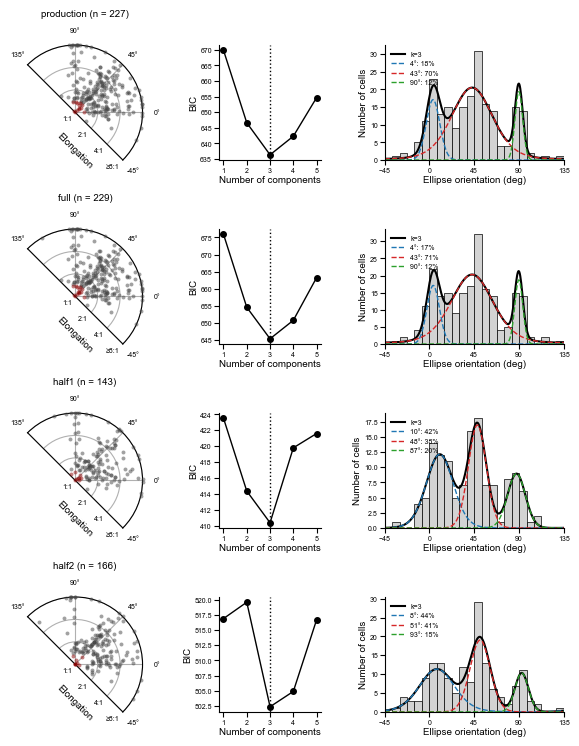

In [ ]:
# Panels K / L / M, one row per variant, same drawing as Fig 3.
N_ANGLE_BINS = 24
angle_edges = np.linspace(-45, 135, N_ANGLE_BINS + 1)
angle_bin_w = np.diff(angle_edges)[0]
angle_grid = np.linspace(-45, 135, 400)
COMPONENT_COLORS = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e"]
fs = FONTSIZE_DICT

fig = plt.figure(figsize=(18 * CM, 5.5 * CM * len(results)))
gs = fig.add_gridspec(len(results), 3, width_ratios=[1.1, 0.8, 1.4], wspace=0.45, hspace=0.6)
for row, (name, r) in enumerate(results.items()):
    sfx, ndf_polar, elong_ok, elongation = r["sfx"], r["ndf_polar"], r["elong_ok"], r["elongation"]
    ax_p = fig.add_subplot(gs[row, 0], projection="polar")
    sc_kwargs = dict(s=8, alpha=0.5, linewidths=0, clip_on=False, zorder=3)
    plot_angle_eccentricity_polar(
        ax_p,
        ndf_polar.loc[elong_ok, f"g2d_theta{sfx}"].astype(float),
        None,
        fs,
        radial_scale="elongation",
        axis_ratio=elongation[elong_ok],
        c="#444444",
        schematics=False,
        **sc_kwargs,
    )
    ax_p.scatter(
        np.radians(ndf_polar.loc[~elong_ok, f"g2d_theta{sfx}"].astype(float)),
        np.clip(np.log2(elongation[~elong_ok]), 0, None),
        c="darkred",
        **sc_kwargs,
    )
    ax_p.set_title(f"{name} (n = {len(ndf_polar)})", fontsize=fs["title"], pad=8)

    ks = sorted(r["bic"])
    ax_b = fig.add_subplot(gs[row, 1])
    ax_b.plot(ks, [r["bic"][k] for k in ks], "o-", color="k", markersize=4, lw=1)
    ax_b.axvline(r["k_best"], color="k", ls=":", lw=1)
    ax_b.set_xticks(ks)
    ax_b.set_xlabel("Number of components", fontsize=fs["label"])
    ax_b.set_ylabel("BIC", fontsize=fs["label"])
    ax_b.tick_params(labelsize=fs["tick"])
    sns.despine(ax=ax_b)

    ax_h = fig.add_subplot(gs[row, 2])
    angles = r["angles"]
    ax_h.hist(angles, bins=angle_edges, color="lightgrey", edgecolor="k", linewidth=0.5)
    best = r["sel"][r["k_best"]]
    pi_k, mu_k, kappa_k = (np.asarray(best[k], dtype=float) for k in ("pi_k", "mu_k", "kappa_k"))
    to_counts = len(angles) * angle_bin_w

    def counts(idx):
        return (
            vm.axial_mixture_density(np.radians(angle_grid), pi_k[idx], mu_k[idx], kappa_k[idx])
            / np.degrees(1)
            * to_counts
        )

    ax_h.plot(angle_grid, counts(slice(None)), color="k", lw=1.5, label=f"k={r['k_best']}")
    mu_deg = wrap_axial_deg(np.degrees(mu_k))
    for rank, i in enumerate(np.argsort(mu_deg)):
        ax_h.plot(
            angle_grid,
            counts([i]),
            color=COMPONENT_COLORS[rank % len(COMPONENT_COLORS)],
            lw=1,
            ls="--",
            label=f"{mu_deg[i]:.0f}°: {100 * pi_k[i]:.0f}%",
        )
    ax_h.set_xlim(-45, 135)
    ax_h.set_xticks([-45, 0, 45, 90, 135])
    ax_h.set_xlabel("Ellipse orientation (deg)", fontsize=fs["label"])
    ax_h.set_ylabel("Number of cells", fontsize=fs["label"])
    ax_h.tick_params(labelsize=fs["tick"])
    ax_h.legend(fontsize=fs["legend"], frameon=False, loc="upper left")
    sns.despine(ax=ax_h)

style.savefig(SAVE_ROOT / "fig_reviewer_treadmill_halves.pdf", fig=fig, bbox_inches="tight")
print(f"Saved {SAVE_ROOT / 'fig_reviewer_treadmill_halves.pdf'}")

half1 kept 134, half2 kept 158, both 109 (Jaccard 0.60)
axial |theta2 - theta1|: median 6.1 deg, within 22.5 deg 84% (uniform chance 25%); mean signed -0.6 deg
shuffled-pairs median |d|: 31.3 deg (95% 24.9-37.2)


PosixPath('/Volumes/BlackPasspo/v1_depth_map/processed/v1_manuscript_figures/ver_rev1/fig_reviewer_treadmill_halves_paired.pdf')

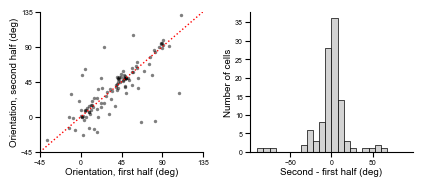

In [ ]:
# Paired comparison: the same neurons in both halves. Cells kept by the Fig 3 selection
# (significant, depth-selective, elongated) in BOTH halves; axial difference of their angles.
h1, h2 = results["half1"], results["half2"]
ids1 = set(h1["ndf_polar"].loc[h1["elong_ok"]].index)
ids2 = set(h2["ndf_polar"].loc[h2["elong_ok"]].index)
both = sorted(ids1 & ids2)
t1 = neurons_df_treadmill.loc[both, f"g2d_theta{h1['sfx']}"].astype(float).to_numpy()
t2 = neurons_df_treadmill.loc[both, f"g2d_theta{h2['sfx']}"].astype(float).to_numpy()
d = (t2 - t1 + 90) % 180 - 90
print(
    f"half1 kept {len(ids1)}, half2 kept {len(ids2)}, both {len(both)} "
    f"(Jaccard {len(both) / len(ids1 | ids2):.2f})"
)
print(
    f"axial |theta2 - theta1|: median {np.median(np.abs(d)):.1f} deg, "
    f"within 22.5 deg {np.mean(np.abs(d) < 22.5):.0%} (uniform chance 25%); "
    f"mean signed {np.mean(d):+.1f} deg"
)
rng = np.random.default_rng(0)
null = [np.median(np.abs((rng.permutation(t2) - t1 + 90) % 180 - 90)) for _ in range(2000)]
print(f"shuffled-pairs median |d|: {np.median(null):.1f} deg (95% {np.percentile(null, 2.5):.1f}-{np.percentile(null, 97.5):.1f})")

fig2, axes = plt.subplots(1, 2, figsize=(11 * CM, 5 * CM))
axes[0].scatter(t1, t2, s=6, c="k", alpha=0.5, linewidths=0)
axes[0].plot([-45, 135], [-45, 135], "r:", lw=1)
for ax_ in (axes[0],):
    ax_.set_xlim(-45, 135)
    ax_.set_ylim(-45, 135)
    ax_.set_xticks([-45, 0, 45, 90, 135])
    ax_.set_yticks([-45, 0, 45, 90, 135])
axes[0].set_xlabel("Orientation, first half (deg)", fontsize=fs["label"])
axes[0].set_ylabel("Orientation, second half (deg)", fontsize=fs["label"])
axes[1].hist(d, bins=np.linspace(-90, 90, 25), color="lightgrey", edgecolor="k", lw=0.5)
axes[1].set_xlabel("Second - first half (deg)", fontsize=fs["label"])
axes[1].set_ylabel("Number of cells", fontsize=fs["label"])
for ax_ in axes:
    ax_.tick_params(labelsize=fs["tick"])
    sns.despine(ax=ax_)
fig2.tight_layout()
style.savefig(SAVE_ROOT / "fig_reviewer_treadmill_halves_paired.pdf", fig=fig2, bbox_inches="tight")